# 15. Correcciones y EDA mejorado con los hallazgos del proyecto

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué hace este capítulo
:class: tip
**Pregunta que responde:** la guía del Entregable 3 pide, sobre esta primera entrega, «realizar todas las
correcciones solicitadas y mejorar el análisis exploratorio con base en nuevos hallazgos encontrados durante el
desarrollo del proyecto» (sección 7.1). ¿Dónde está cada corrección y qué agregan al EDA los Entregables 2 y 3?

**Datos:** la misma partición del capítulo 2 y, como en todo el EDA, **solo el entrenamiento** (257 273
viviendas). La única excepción es la sección 15.4, un diagnóstico de la composición del test que se hizo
**después** de evaluar los modelos y que no se usa para ninguna decisión.

**Recorrido:** las correcciones y dónde están (15.1); el entorno de la vivienda (15.2); las fronteras entre
estratos (15.3); la composición del test (15.4); a qué distancia se predice (15.5); qué decisiones cambian (15.6).
```

## 15.1 Las correcciones de la primera entrega y dónde están

| Corrección | Qué cambió | Dónde |
|---|---|---|
| **Viviendas sin coordenadas** | El 16 % de las viviendas (casi todas informales de estratos 1 y 2) no tenía coordenadas y quedaba fuera. Se ubican por el centroide de su manzana cuando la manzana es compacta: la cobertura sube del 83.8 % al 96.9 % y la del estrato 1, del 67 % al 92 %. | Versión 2: capítulo 1 (sección 1.7) y apéndice A.13 |
| **Grupo del ICC** | Las mejoras en terreno ajeno se agrupaban por un prefijo del NPN que reunía viviendas independientes. Ahora cada mejora es su propio grupo: ICC 0.992, efecto de diseño ≈ 144, unas 2 300 viviendas independientes. | Apéndice A.11 |
| **Variables de pisos** | `total_plantas` son los pisos de la propia vivienda (1 en casi todos los apartamentos), `planta_ubicacion` el piso de la unidad y `altura` casi constante (3 m). | Diccionario del capítulo 1 y limitaciones (11.2) |
| **Dos universos de datos** | Las estadísticas de la base completa y las del universo con coordenadas se reportan por separado. | Apéndice A.12 |
| **Validación con vecinos más cercanos** (sugerencia del profesor) | El buffer fijo de 1 km evaluaba a 1.4–1.5 km del dato más cercano, más lejos que el escenario real (0.45 km). La validación kNNDM reproduce esa distancia; el modelo base se reajusta con ella (F1 de test 0.493, MAE ordinal 0.384). | Versión 3: capítulo 14 y apéndice A.14 |

Las secciones siguientes son la segunda parte del pedido: **lo que el EDA no había visto** y que aprendimos al
construir los modelos de los Entregables 2 y 3.

In [1]:
# Preparación: mismas importaciones y datos que el resto del libro.
import json
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

from src import config as C
from src import estadistica as E
from src import graficos as G
from src import particion as P
from src import vecinos as V

G.estilo()
C.aviso_sintetico()
datos = P.cargar_particion()
train = datos[datos.particion == "train"].reset_index(drop=True)
test = datos[datos.particion == "test"].reset_index(drop=True)
y = train[C.OBJETIVO].to_numpy()
print(f"Entrenamiento: {len(train):,} viviendas | prueba: {len(test):,} (solo para la sección 15.4)")

Entrenamiento: 257,273 viviendas | prueba: 65,145 (solo para la sección 15.4)


## 15.2 Hallazgo 1: el entorno de la vivienda dice más del estrato que la vivienda misma

El EDA del capítulo 6 midió la relación de cada variable de la vivienda con el estrato. En el Entregable 2
apareció una pregunta que el EDA no se había hecho: **¿cómo son las viviendas de alrededor?** Para cada vivienda se
calcula el promedio de seis atributos en sus **8 edificios más cercanos** (sin contar su propio edificio y sin
usar el estrato de nadie): área construida (log), baños, habitaciones, antigüedad, piso y proporción en propiedad
horizontal, más la distancia media a esos 8 edificios. Es la **vecindad física** que usan los Entregables 2 y 3.

La tabla compara el tamaño del efecto (η² de Kruskal-Wallis, capítulo 6) de cada atributo de la propia vivienda
con el del mismo atributo promediado en sus vecinos.

In [2]:
xy = train[["x_km", "y_km"]].to_numpy()
xy_g, n_g, cod = V.puntos_unicos(xy, train.npn_edificio.to_numpy())
attrs = pd.DataFrame({
    "área construida (log)": np.log1p(train.area_construida), "baños": train.total_banios,
    "habitaciones": train.total_habitaciones, "antigüedad": train.antiguedad, "piso": train.planta_ubicacion,
    "propiedad horizontal": (train.condicion_predio == "PH_Unidad_Predial").astype(float)})
attrs = attrs.fillna(attrs.median())
A_g = attrs.groupby(cod).mean().to_numpy()
g = np.arange(len(xy_g))
lag, dist = V.lag_knn(xy_g, xy_g, A_g, 8, grupo_destino=g, grupo_fuente=g)
vec = pd.DataFrame(lag[cod], columns=attrs.columns)
df_propia = pd.concat([attrs, train[[C.OBJETIVO]]], axis=1)
df_vec = pd.concat([vec, train[[C.OBJETIVO]]], axis=1)
filas = {}
for c in attrs.columns:
    filas[c] = {"η² de la propia vivienda": E.kruskal_eta2(df_propia, c, C.OBJETIVO)["eta2_H"],
                "η² de sus 8 vecinos": E.kruskal_eta2(df_vec, c, C.OBJETIVO)["eta2_H"]}
tabla_eta = pd.DataFrame(filas).T
tabla_eta["cuántas veces más"] = tabla_eta["η² de sus 8 vecinos"] / tabla_eta["η² de la propia vivienda"]
dist_vec = pd.DataFrame({"d": dist[cod], C.OBJETIVO: y})
print(f"Distancia media a los 8 edificios vecinos: η² = {E.kruskal_eta2(dist_vec, 'd', C.OBJETIVO)['eta2_H']:.3f}")
tabla_eta.round(3)

Distancia media a los 8 edificios vecinos: η² = 0.264


,η² de la propia vivienda,η² de sus 8 vecinos,cuántas veces más
área construida (log),0.166,0.445,2.688
baños,0.330,0.601,1.824
habitaciones,0.079,0.264,3.355
antigüedad,0.046,0.065,1.396
piso,0.244,0.308,1.261
propiedad horizontal,0.293,0.377,1.288


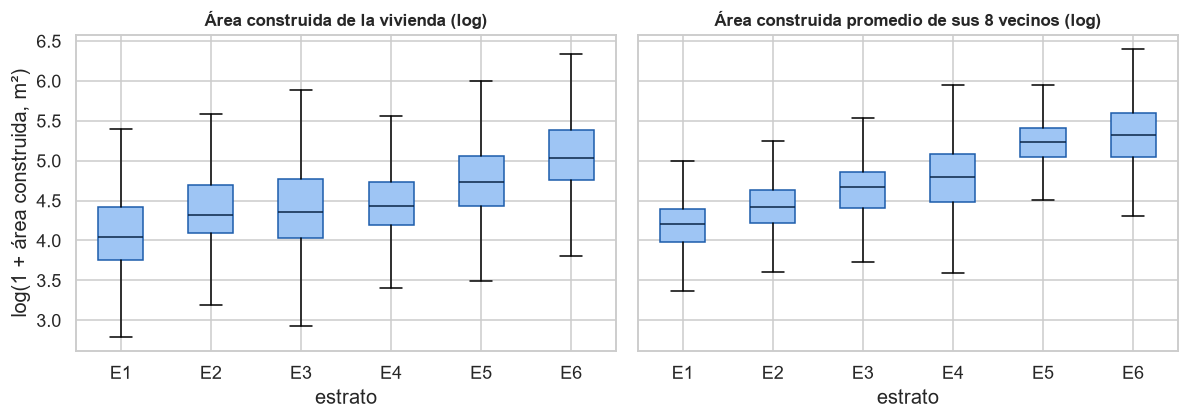

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (titulo, serie) in zip(axes, [("Área construida de la vivienda (log)", attrs["área construida (log)"]),
                                      ("Área construida promedio de sus 8 vecinos (log)", vec["área construida (log)"])]):
    datos_cajas = [serie[y == k] for k in C.CLASES]
    ax.boxplot(datos_cajas, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#9ec5f4", color="#1c5cab"), medianprops=dict(color="#0a2547"))
    ax.set_xticks(range(1, 7), [f"E{k}" for k in C.CLASES])
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("estrato")
axes[0].set_ylabel("log(1 + área construida, m²)")
plt.tight_layout()
plt.show()

**Lectura.** **En los seis atributos, el promedio de los vecinos se relaciona con el estrato más que el atributo de
la propia vivienda**: los baños de los vecinos tienen η² = 0.60 frente a 0.33 de los baños propios, y el área de
los vecinos, 0.45 frente a 0.17 (2.7 veces más). Incluso la distancia media a los 8 edificios vecinos, una medida
de densidad, tiene η² = 0.26. Las cajas lo muestran: el área propia se solapa mucho entre estratos (una casa
pequeña puede estar en cualquier barrio), mientras que el área de los vecinos ordena los estratos de forma casi
monótona.

Es lo que anticipaba la metodología del DANE (el estrato es una propiedad de la zona, apéndice A.1) y lo que
confirmaron los modelos: agregar estas variables subió el F1 de test de la logística de 0.49 a 0.57–0.60
(Entregable 2), y en el análisis SHAP del Entregable 3 las variables más importantes son la posición norte-sur, el
área y los baños de los vecinos y la distancia al centro; la primera variable propia de la vivienda aparece en el
décimo lugar.

## 15.3 Hallazgo 2: las fronteras entre estratos

Si el estrato es de la zona, las viviendas difíciles de clasificar deberían estar donde las zonas se tocan. Para
cada edificio se toma su estrato (el más frecuente entre sus viviendas) y se cuenta cuántos de sus 8 edificios
más cercanos tienen otro estrato.

In [4]:
moda_g = pd.Series(y).groupby(cod).agg(lambda s: s.mode().iloc[0]).to_numpy()
_, idx = cKDTree(xy_g).query(xy_g, k=9)
idx = idx[:, 1:]
otro = moda_g[idx] != moda_g[:, None]
salto = np.abs(moda_g[idx] - moda_g[:, None])
fr = pd.DataFrame({C.OBJETIVO: y, "prop_otro": otro.mean(1)[cod], "frontera": otro.mean(1)[cod] >= 0.5})
tabla_fr = fr.groupby(C.OBJETIVO).agg(**{"vecinos con otro estrato (media)": ("prop_otro", "mean"),
                                        "% de viviendas en frontera": ("frontera", "mean")})
tabla_fr["% de viviendas en frontera"] *= 100
tabla_fr.loc["todas"] = [fr.prop_otro.mean(), 100 * fr.frontera.mean()]
print(f"Entre los vecinos con otro estrato, el {100 * (salto[otro] == 1).mean():.1f} % difiere en un solo estrato.")
tabla_fr.round(3)

Entre los vecinos con otro estrato, el 95.7 % difiere en un solo estrato.


,vecinos con otro estrato (media),% de viviendas en frontera
estrato_num,,
1,0.193,18.693
2,0.194,18.304
3,0.214,21.870
4,0.281,29.844
5,0.391,43.563
6,0.244,20.340
todas,0.223,22.304


**Lectura.** El **22 %** de las viviendas de entrenamiento está en una **frontera**: la mitad o más de sus 8
edificios vecinos tiene otro estrato. No todos los estratos viven igual: el **estrato 5 es el más fronterizo**
(44 % de sus viviendas), seguido del 4 (30 %); los estratos 1 y 2 son los más homogéneos (18–19 %). Y casi
todas esas fronteras son de **un solo estrato** (el 96 % de los vecinos con otro estrato difiere en uno).

Este hallazgo explica tres resultados posteriores: los errores de los modelos son casi siempre de un estrato
(accuracy ±1 de 0.96 a 0.99), el estrato 5 es el que peor reconoce el modelo base (recall 0.08 en la versión 3,
capítulo 14) y **ADASYN** fue el peor método de balanceo en el
Entregable 3, porque concentra los ejemplos sintéticos en las viviendas «difíciles», que aquí son las de frontera.

## 15.4 Hallazgo 3: el test no tiene la misma composición que el entrenamiento

```{admonition} Diagnóstico posterior, no una decisión
:class: warning
Esta sección mira las etiquetas del test. Se hizo **después** de evaluar los modelos de los Entregables 2 y 3,
para entender por qué su F1 de test difiere de la validación; no cambia ninguna decisión del EDA ni del modelo.
```

In [5]:
comp = pd.DataFrame({"entrenamiento (%)": train[C.OBJETIVO].value_counts(normalize=True).sort_index() * 100,
                     "prueba (%)": test[C.OBJETIVO].value_counts(normalize=True).sort_index() * 100})
display(comp.round(1).T)
por_bloque = pd.crosstab(test.bloque, test[C.OBJETIVO]).rename(columns=lambda k: f"E{k}")
por_bloque["total"] = por_bloque.sum(1)
por_bloque

estrato_num,1,2,3,4,5,6
entrenamiento (%),30.0,22.7,22.9,14.4,5.2,4.8
prueba (%),35.4,20.3,19.1,18.8,5.2,1.2


estrato_num,E1,E2,E3,E4,E5,E6,total
bloque,,,,,,,
1006,119,3772,1116,1,0,0,5008
2002,14953,1283,0,0,0,0,16236
2004,6618,4570,2907,2,0,0,14097
3002,3,0,0,0,0,0,3
3004,1394,3051,7313,1915,6,0,13679
4004,0,7,1054,10332,3361,793,15547
6005,4,509,62,0,0,0,575


**Lectura.** El test tiene más estrato 1 (35 % frente a 30 %) y mucho menos estrato 6: **1.2 % frente a 4.8 %**.
Y las **793 viviendas de estrato 6 del test están todas en un solo bloque** (el 4004), igual que casi todas las de
estrato 5. Además, un bloque tiene solo 3 viviendas.

Consecuencias para leer los resultados: el F1 macro da el mismo peso a los seis estratos, así que el F1 del
estrato 6, que pesa un sexto del total, depende de **un solo bloque**. Por eso los intervalos de confianza del test
son anchos y asimétricos, la validación (con 4.8 % de estrato 6) y el test no siempre ordenan igual a los modelos,
y con 7 bloques ninguna diferencia pequeña entre modelos puede declararse significativa después de corregir por
comparaciones múltiples (Entregable 3, capítulo 11). No es un error de la partición, que se hizo antes de mirar
nada (capítulo 2): es una limitación del tamaño del test que conviene tener presente.

## 15.5 Hallazgo 4: a qué distancia se predice

El capítulo 8 midió que el estrato se parece hasta unos 2.6 km. El capítulo 14 agregó la pregunta que importa para
validar: **¿a qué distancia del dato más cercano tendrá que predecir el modelo?**

In [6]:
r3 = json.loads((RAIZ / "datos" / "procesados" / "resultados_v3.json").read_text(encoding="utf-8"))
dist_tab = pd.DataFrame(r3["distancias"]["cuantiles"]).T
dist_tab[["p10 (km)", "mediana (km)", "p90 (km)"]].round(3)

,p10 (km),mediana (km),p90 (km)
Escenario: zona nueva de 2 km (test → todo train),0.107,0.453,0.819
Test de la versión 2 (test → train tras buffer),1.103,1.532,2.013
CV de la versión 2 (bloques + buffer de 1 km),1.074,1.406,2.075
CV aleatoria por edificios,0.000,0.010,0.109
CV kNNDM (versión 3),0.104,0.464,1.227


**Lectura.** Una zona nueva de 2 km se predice, en la mediana, a **0.45 km** de la vivienda de entrenamiento más
cercana. La validación con buffer de 1 km evaluaba a 1.41 km y el test de la versión 2 a 1.53 km: medían un
escenario más difícil que el real. Una validación aleatoria, en cambio, evalúa a 0.01 km (vecinos del mismo
edificio) y por eso casi duplicaba el F1. La validación kNNDM evalúa a 0.46 km, como el escenario, y es la que
usan los Entregables 2 y 3.

## 15.6 Qué decisiones cambian con estos hallazgos

| Hallazgo | Decisión | Dónde se aplica |
|---|---|---|
| El entorno dice más que la vivienda (15.2) | Agregar la **vecindad física** (8 vecinos) como variables | Entregable 2 (cap. 7) y todos los modelos del Entregable 3 |
| Las fronteras concentran la dificultad (15.3) | Preferir `class_weight` a ADASYN; reportar métricas ordinales (los errores son de un estrato) | Entregable 3 (cap. 5) |
| El test tiene un solo bloque con estrato 6 (15.4) | Intervalos por bloques, conclusiones solo si validación y test coinciden, pruebas con más bloques en la validación | Entregables 2 y 3 |
| Se predice a 0.45 km (15.5) | Validación kNNDM en lugar del buffer de 1 km | Capítulo 14 y Entregables 2 y 3 |

Con esto, el EDA de la primera entrega queda corregido (15.1) y ampliado con lo que el proyecto aprendió después:
el estrato es una propiedad de la **zona**, se decide en las **fronteras** entre zonas, y el test, con solo 7
bloques, mide esa frontera de forma desigual.